# Benchmarking ALLA against LLM-driven agents

## 1. Speed vs accuracy on a zero-shot "easy", "pre-trained" classification/model selection problem

Each task involves producing a growth forecast for a sample (synthetic) company. The forecast is to be represented as five scenarios:

* Worst (2.5% quantile);
* Bad (16% quantile);
* Base (50% quantile, aka median);
* Good (84% quantile);
* Best (97.5% quantile).

There are three class of company: hyperscalers, steady-staters, and time-bombs. Given the company class, the growth is normally distributed around a constant (ie, a Gaussian mixture model), therefore the forecast *assuming* a certain class is merely a lookup on a table. (However, the optimal solution is given by the quantiles of the mixture distribution.) In particular, in this simplified setting, historical growth does **not** directly matter for the forecast.

The classification can be inferred from a combination of binary indicators, which can be gleaned from the company's public information book (PIB). The indicators can be "hard" (comparing a certain quantity in the PIB with a given threshold) or "soft" (finding enough evidence of a certain pro or con).

(Hard mode: rather than simple binary thresholds, treat the hard indicators as GMM components.)

All agents above are given the same inference budget (ie, wall time) per task, which is varied in the study.

The **LLM-driven baseline** is given the task explanation, including all the required details (ie, the lookup table, indicator definitions etc), and fed the tasks one at a time, and asked to solve them in a streaming manner, taking the last answer until inference terminates or the inference budget runs out.

LLM ablations:
* Different LLMs, context windows, etc.
* Let the LLM amortize/learn in-context: give it the task description once and tell it to create a solution plan, then ask it to solve the tasks (ie, forecast growth scenarios) in turn.
* Pair the LLM with a "critic" which reviews its answers.
* Let the LLM write code and invoke a code interpreter (ad hoc).

**ALLA with online model construction (ours)** does the following:
  * Invokes an LLM, with the same task explanation and details, and asks it to generate a GMM model in PyMC to use in the below.
  * Prioritizes the indicators in terms of their value, which in this case is just the expected effect on the growth distribution. (KL divergence?)
    * (Michael) I'm a bit confused here. Is indicator-ranking/significance something we will be explicitly modeling? If not, how is this achieved? How important it this step if ALLA just takes everything in regardless?
  * Estimates indicators' expected cost according to a simple heuristic: some large constant value for each "soft" indicator, some small constant value for each "hard" indicator.
    * (Michael) Cost in terms of resource budget?
  * Calculates net value for each indicator.
  * For each task:
    * Calculates indicators in order of net value, until the inference budget is close to running out ("model reduction").
    * If indicators have been all calculated and some inference budget is left over, use it to re-infer "soft" indicators to smooth out LLM noise.
    * Infers class probabilities from the last indicator values.
    * Calculates the quantiles according to the inferred class probabilities. (Quantiles for scalar GMM can be calculated using a simple line search.)

ALLA pays a handicap corresponding to the upfront GMM generation time.

**ALLA with handcrafted model (ours)** is the same as ALLA but uses a handcrafted model that is pre-validated.

ALLA ablations:
* Access to an oracle for soft indicator values, with a predetermined (known) error rate.
* Tasks given as natural language instead of JSON, requiring ALLA to pay an extra extraction penalty?

### Scoring
Each task is scored as follows:
* 0 points if Actual < Worst, or Actual > Best, or no answer is provided.
* 1 point if Worst <= Actual < Bad or Good < Actual <= Best.
* 3 points if Bad <= Actual <= Good.

#### Alternative scoring: (Negative) sum of quantile losses, ie, $-\sum_\alpha L(g_{\text{actual}}; g_\alpha)$

### Hypotheses:
* ALLA will outperform LLMs *shockingly* for small inference budgets, even taking into account the handicap. It will correctly squeeze all the value out of hard indicators before attempting to use soft ones, getting to much closer answers.
* ALLA will also outperform LLMs for large inference budgets, both because it only needs to use up the expensive token generation cost on the soft indicator calculation, and because it has crystallized the correct model structure.
* The LLM critic will help at large inference budgets, but not that much.
* Even LLM + code interpreter will struggle, because it doesn't have the crystallized model structure but must instead generate code ad hoc each time.
* LLMs will likely get distracted by irrelevant details (ex: will insist on running regressions on the financials).

## 2. Many-shot didactic learning from case studies

In this case, models are not given any of the details *a priori*. They know the task structure, but must learn the details (the different company classes -- even the number of which are unknown *a priori*, the corresponding values of the lookup table, and the indicator definitions) from a series of case studies before they are exposed to the test tasks. The case studies also give a short theoretical explanation of each.

The LLM-driven baseline will attempt to learn the details in-context, by continuously regenerating a best-guess lookup table and the indicator definitions as it tries to analyze the case studies.

LLM ablations: as in #1.

ALLA will merely fit the hard indicator thresholds and GMM components, and store the soft indicator rules for further use. It can also update the model structure code through additional LLM calls (using the explanatory knowledge) if unexpected behavior shows up.

ALLA ablations: as in #1.


### Hypotheses:
* LLM-driven agent will barely be able to compete on this one. Even if it can correctly keep track of the mean growth values and indicators, generating quantiles requires fitting the normal components, which AFAIK can't be done on LLMs.
* LLM + code generator can do better if they have enough time to think and iterate.

## 3. (Bonus) Zero-shot continuous learning

Same as above, except that there is no upfront training with case studies. Instead, for each task:
* The model is first given the task PIB and asked to produce an answer;
* The model is scored on its answer;
* The model is then given the correct answer and allowed to process it before the next task.

### Hypotheses:
* This is even harder for a pure LLM. Possibly the LLM + code generator will not see a drop in performance?
* Meanwhile, ALLA will start poorly but get up to speed quickly.

# Ways in which this is an unfair comparison
* **Favoring ALLA over LLMs:**
  * One could argue that ALLA can only work if the fine causal structure of the model is "known" at task time, whereas the LLM "can solve" any task that is thrown at it. As #2 shows, this is not as restrictive as it seems at first glance -- ALLA can easily update its model at task time to accommodate for extra classes or indicators, for instance. Therefore, this implementation of ALLA generalizes to *any* task that can be described as above, as there is enough explanatory knowledge available for it to incrementally extend the model correctly (whether it is embedded into case studies as above, or learned *a priori* as in the didactic-first approach of previous demos). And it is easy to see how a fully general implementation will obtain by progressively abstracting and composing models (as described in the whitepaper).
  * The all-important question of "figure out what to do to make the user happy" doesn't exist for ALLA -- it simply gets an object `task` and calls `answer = infer(model, task)`. Meanwhile, the LLM can go wrong right out of the gate with a wrong [frame](plato.stanford.edu/entries/frame-problem), especially if it's mis-prompted. But far from pointing to a problem with the current benchmark, this actually highlights the crux of our argument:
    * If, at the task entry point, the top-level agent has *a priori* knowledge of the task structure, then it's silly for it to just encode that knowledge as prompt tokens and letting the language sub-agent drown in ambiguity. Instead, the agent should first up-front encode the task structure as a crystallized world model, such that the task inputs can be immediately parsed into structured JSON objects with a well-defined interpretation -- ie, there is a well-defined (if stochastic) mapping `task_inputs --> model_function_name, model_args`, where the latter are documented in an explicit and legible ontology.
      * By the way, a sub-complaint could be that the task presented here is particularly trivial in the framing department, as there's a single model to select from. But in fact, this is false: the top-level model is hierarchical, and therefore just the entry point for a (stochastic) tree of such mappings: `task_inputs --> (infer_company_class, {indicators: task_inputs[indicators]}) --|class_probs|> (infer_growth, {class_probs: class_probs})`.

      ```mermaid
      task_inputs --> (infer_company_class, {indicators: task_inputs[indicators]}) --|class_probs|> (infer_growth, {class_probs: class_probs})```
    * Even if the exact task structure is not known, whatever meta-structure is available should be encoded, so that, as more tasks come in, the agent can incrementally update the world model (as described in the previous point).
    * The "ChatGPT approach" of
  * Because we're dealing with synthetic data produced from a simplified model structure, LLMs might make mistakes caused by them overcomplicating things based on their pretraining (ex: running irrelevant regressions). Again, the fact that LLMs can't reliably ignore data that is a priori known to be irrelevant to the task at hand is part of the advantage of using something like ALLA.
* **Favoring LLMs over ALLA:**
  * We could counter that LLMs have it easy, because the numerical part of the task is about as simple as it gets in real analysis situations: the classification involves only scalar comparisons and conjunctions/disjunctions (ie, a decision tree), and the class-dependent forecasting requires only finding the mean and variance of each class component distribution (instead of an actual regression as would be required in real-life scenarios).
  * It's also a rather plausible, if stylized, set of problems, so in principle LLM's ability to generate plausible answers for "the wrong reasons" should play in their favor.
  * This is even more favorable when LLMs get access to a code interpreter; there's no excuse to not get any of these answers right if you claim to actually "understand" what is going on and can write the code.

# Project tracking on Slack


# 1. Synthetic data generation (easy mode)

In [ ]:
import arviz as az
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import pymc as pm

from scipy.stats import norm
from xarray_einstats.stats import XrContinuousRV

%config InlineBackend.figure_format = 'retina'
RANDOM_SEED = 8927
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-darkgrid")

In [ ]:
# Core independent indicators with more realistic bounds
independent_indicator_intervals = {
    # Profitability fundamentals (even troubled companies rarely go below -0.2)
    'gross_margin': {
        'red': (-0.2, 0.15),
        'yellow': (0.15, 0.40),
        'green': (0.40, 0.80)
    },
    'operating_margin': {
        'red': (-0.2, 0.05),
        'yellow': (0.05, 0.20),
        'green': (0.20, 0.45)
    },

    # Capital structure and efficiency
    'asset_turnover': {
        'red': (0.2, 0.5),
        'yellow': (0.5, 2.0),
        'green': (2.0, 4.0)
    },
    'leverage': {
        'red': (2.0, 5.0),
        'yellow': (0.5, 2.0),
        'green': (0.1, 0.5)
    },

    # Growth metrics (more realistic bounds)
    'revenue_growth': {
        'red': (-0.3, 0.0),
        'yellow': (0.0, 0.20),
        'green': (0.20, 0.50)
    },
    'ebitda_growth': {
        'red': (-0.4, -0.05),
        'yellow': (-0.05, 0.15),
        'green': (0.15, 0.60)
    },

    # Operational efficiency
    'working_capital_ratio': {
        'red': (0.5, 1.0),
        'yellow': (1.0, 2.0),
        'green': (2.0, 4.0)
    },
    'reinvestment_rate': {
        'red': (0.0, 0.15),
        'yellow': (0.15, 0.75),
        'green': (0.75, 1.2)
    }
}

In [ ]:
def sample_independent_indicators(specified_colors=None):
    """
    Generate random values for independent indicators based on specified interval colors,
    defaulting to yellow for unspecified indicators.

    Args:
        specified_colors (dict): Dictionary mapping indicator names to colors ('red', 'yellow', 'green')

    Returns:
        dict: Dictionary with random values for independent indicators only
    """
    if specified_colors is None:
        specified_colors = {}

    # Only sample independent indicators
    result = {}
    for indicator, intervals in independent_indicator_intervals.items():
        color = specified_colors.get(indicator, 'yellow')
        lower, upper = intervals[color]

        # Sample based on indicator type
        if indicator in ['revenue_growth', 'ebitda_growth']:
            # Growth rates: beta distribution for more realistic values
            # Transform beta distribution to match our interval
            alpha = 2
            beta = 3 if color == 'red' else (2 if color == 'yellow' else 1.5)
            value = (upper - lower) * np.random.beta(alpha, beta) + lower

        elif indicator in ['working_capital_ratio', 'leverage']:
            # Ratios: log-normal for positive skew
            mu = np.log((lower + upper) / 2)
            sigma = 0.4  # Reduced from 0.5 for less extreme values
            value = min(upper, max(lower, np.random.lognormal(mu, sigma)))

        else:
            # Other metrics: uniform distribution
            value = np.random.uniform(lower, upper)

        result[indicator] = round(value, 3)

    return result

In [ ]:
# Example usage:
specified = {
    'leverage': 'red',
    'revenue_growth': 'green'
}

values = sample_independent_indicators(specified)
for k, v in sorted(values.items()):
    print(f"{k}: {v}")

asset_turnover: 1.556
ebitda_growth: -0.017
gross_margin: 0.354
leverage: 2.544
operating_margin: 0.119
reinvestment_rate: 0.3
revenue_growth: 0.289
working_capital_ratio: 2.0


In [ ]:
    # Define default tolerance thresholds (tighter for core metrics, looser for derived ones)
    DEFAULT_TOLERANCES = {
        # Core profitability metrics - tight tolerance
        'operating_margin': 0.05,    # 5% relative error
        'gross_margin': 0.05,
        'net_profit_margin': 0.05,

        # Core balance sheet metrics - tight tolerance
        'leverage': 0.05,
        'working_capital_ratio': 0.10,

        # Core return metrics - moderate tolerance
        'roic': 0.10,
        'roe': 0.10,
        'cfroi': 0.15,

        # Growth metrics - looser tolerance due to compounding effects
        'revenue_growth': 0.15,
        'fcf_growth': 0.20,
        'ebitda_growth': 0.20,

        # Efficiency metrics - moderate tolerance
        'asset_turnover': 0.15,
        'reinvestment_rate': 0.15,

        # Market-based metrics - looser tolerance due to interdependencies
        'pe_ratio': 0.20,
        'ev_ebitda': 0.20,
        'pb_ratio': 0.20,

        # Derived metrics - looser tolerance
        'eva_percent': 0.25,

        # Cash conversion - moderate tolerance
        'cash_conversion_cycle': 0.15
    }

In [ ]:
def calculate_derived_indicators(independent_indicators):
    """
    Calculate derived indicators from independent ones.

    Args:
        independent_indicators: Dictionary of independent indicators

    Returns:
        Dictionary containing all indicators (independent and derived)
    """
    # Constants
    TAX_RATE = 0.25
    COST_OF_DEBT = 0.05
    COST_OF_EQUITY = 0.10

    # Start with copy of independent indicators
    all_indicators = independent_indicators.copy()

    # 1. Calculate WACC
    leverage = all_indicators['leverage']
    wacc = (COST_OF_EQUITY * 1/(1 + leverage) +
            COST_OF_DEBT * (1 - TAX_RATE) * leverage/(1 + leverage))

    # 2. Calculate interest burden based on leverage
    interest_burden = leverage * COST_OF_DEBT / (1 + leverage)

    # 3. Calculate net profit margin from operating margin
    all_indicators['net_profit_margin'] = (
        all_indicators['operating_margin'] *
        (1 - TAX_RATE) *
        (1 - interest_burden)
    )

    # 4. Calculate ROIC from operating margin and asset turnover
    all_indicators['roic'] = (
        all_indicators['operating_margin'] *
        all_indicators['asset_turnover'] *
        (1 - TAX_RATE)
    )

    # Use small positive number if ROIC is zero to avoid division issues
    roic_for_calc = all_indicators['roic'] if all_indicators['roic'] != 0 else 1e-6

    # Calculate ROE from ROIC and leverage
    all_indicators['roe'] = (
        roic_for_calc * (1 + leverage) -
        (COST_OF_DEBT * leverage * (1 - TAX_RATE))
    )

    # Calculate CFROI based on ROIC and reinvestment
    all_indicators['cfroi'] = roic_for_calc * (1 - all_indicators['reinvestment_rate'])

    # Calculate valuation metrics using growth and returns
    growth_factor = (all_indicators['revenue_growth'] + all_indicators['ebitda_growth']) / 2
    growth_for_calc = growth_factor if growth_factor < wacc else wacc - 1e-6

    # PE ratio using simplified Gordon growth
    all_indicators['pe_ratio'] = (1 + growth_for_calc) / (wacc - growth_for_calc)

    # EV/EBITDA roughly tracks with PE but typically lower
    all_indicators['ev_ebitda'] = all_indicators['pe_ratio'] * 0.8

    # P/B ratio follows from ROE and PE
    all_indicators['pb_ratio'] = all_indicators['pe_ratio'] * all_indicators['roe']

    # 8. Calculate FCF growth based on EBITDA growth and reinvestment
    all_indicators['fcf_growth'] = (
        all_indicators['ebitda_growth'] *
        (1 - 0.1)  # Assume 10% change in reinvestment rate
    )

    return all_indicators

In [ ]:
def generate_financials(independent_indicators):
    """
    Generate synthetic financial statements that are consistent with given financial indicators.
    Uses revenue as the anchor and derives other values to maintain ratio consistency.

    Args:
        independent_indicators (dict): Dictionary of financial indicators

    Returns:
        dict: Dictionary containing P&L, balance sheet, and market data
    """
    # Constants
    TAX_RATE = 0.25

    # First calculate all derived indicators
    indicators = calculate_derived_indicators(independent_indicators)

    # STEP 1: Revenue and Income Statement
    # This is our base scale and determines all absolute values
    base_revenue = np.random.uniform(100e6, 10e9)

    income_statement = {
        'revenue': base_revenue,
        'gross_profit': base_revenue * indicators['gross_margin'],
        'operating_income': base_revenue * indicators['operating_margin'],
        'net_income': base_revenue * indicators['net_profit_margin']
    }

    # Add EBITDA components
    da_rate = np.random.uniform(0.2, 0.4)
    income_statement['depreciation_amortization'] = income_statement['operating_income'] * da_rate
    income_statement['ebitda'] = income_statement['operating_income'] + income_statement['depreciation_amortization']

    # STEP 2: Capital Structure and Balance Sheet
    # Start with equity from ROE (this will ensure ROE is exact)
    balance_sheet = {}
    balance_sheet['total_equity'] = income_statement['net_income'] / indicators['roe']

    # Debt from leverage target (this ensures leverage is exact)
    balance_sheet['total_debt'] = balance_sheet['total_equity'] * indicators['leverage']

    # Total assets from asset turnover (this ensures asset turnover is exact)
    balance_sheet['total_assets'] = income_statement['revenue'] / indicators['asset_turnover']

    # STEP 3: Operating Capital Components
    # Calculate NOPAT and invested capital from ROIC
    nopat = income_statement['operating_income'] * (1 - TAX_RATE)
    roic_for_calc = indicators['roic'] if indicators['roic'] != 0 else 1e-6
    invested_capital = nopat / roic_for_calc

    # Split invested capital into working capital and fixed capital
    working_capital_percent = 0.3  # Assume 30% of invested capital is working capital
    target_working_capital = invested_capital * working_capital_percent

    # Handle working capital ratio calculations more safely
    # If ratio is R, then:
    # current_assets = R * current_liabilities
    # working_capital = current_assets - current_liabilities = target_working_capital
    # Therefore: target_wc = R*CL - CL = CL*(R-1)
    # So: CL = target_wc/(R-1) but we need to handle R ≈ 1 carefully

    wcr = indicators['working_capital_ratio']
    if abs(wcr - 1.0) < 0.01:  # If ratio is very close to 1
        # Use a reasonable default relationship
        balance_sheet['current_liabilities'] = target_working_capital
        balance_sheet['current_assets'] = target_working_capital * wcr
    else:
        balance_sheet['current_liabilities'] = abs(target_working_capital / (wcr - 1))
        balance_sheet['current_assets'] = balance_sheet['current_liabilities'] * wcr

    balance_sheet['working_capital'] = balance_sheet['current_assets'] - balance_sheet['current_liabilities']

    # Fixed assets (balancing item for invested capital)
    balance_sheet['fixed_assets'] = invested_capital - balance_sheet['working_capital']

    # STEP 4: Cash Flows
    # Use CFROI to determine operating cash flow (this ensures CFROI is exact)
    cash_flow = {
        'operating_cash_flow': invested_capital * indicators['cfroi'],
        # Use reinvestment rate to determine capex (this ensures reinvestment rate is exact)
        'capex': -income_statement['net_income'] * indicators['reinvestment_rate']
    }
    cash_flow['free_cash_flow'] = cash_flow['operating_cash_flow'] + cash_flow['capex']

    # STEP 5: Market Values
    # Start with P/E to get market cap (this ensures P/E is exact)
    market_data = {
        'market_cap': income_statement['net_income'] * indicators['pe_ratio'],
        # Use EV/EBITDA to get enterprise value (this ensures EV/EBITDA is exact)
        'enterprise_value': income_statement['ebitda'] * indicators['ev_ebitda'],
        'book_value': balance_sheet['total_equity'],
        'shares_outstanding': np.random.uniform(50e6, 1e9)
    }
    market_data['price_per_share'] = market_data['market_cap'] / market_data['shares_outstanding']

    # STEP 6: Previous Period Values for Growth Metrics
    prev_period = {
        'revenue': base_revenue / (1 + indicators['revenue_growth']),
        'fcf': cash_flow['free_cash_flow'] / (1 + indicators['fcf_growth']),
        'ebitda': income_statement['ebitda'] / (1 + indicators['ebitda_growth'])
    }

    # Verification calculations
    verification = {
        'roic_calc': nopat / (invested_capital if invested_capital != 0 else 1e-6),
        'operating_margin_calc': income_statement['operating_income'] / (income_statement['revenue'] if income_statement['revenue'] != 0 else 1e-6),
        'gross_margin_calc': income_statement['gross_profit'] / (income_statement['revenue'] if income_statement['revenue'] != 0 else 1e-6),
        'net_profit_margin_calc': income_statement['net_income'] / (income_statement['revenue'] if income_statement['revenue'] != 0 else 1e-6),
        'leverage_calc': balance_sheet['total_debt'] / (balance_sheet['total_equity'] if balance_sheet['total_equity'] != 0 else 1e-6),
        'working_capital_ratio_calc': balance_sheet['current_assets'] / (balance_sheet['current_liabilities'] if balance_sheet['current_liabilities'] != 0 else 1e-6),
        'asset_turnover_calc': income_statement['revenue'] / (balance_sheet['total_assets'] if balance_sheet['total_assets'] != 0 else 1e-6),
        'revenue_growth_calc': (income_statement['revenue'] / (prev_period['revenue'] if prev_period['revenue'] != 0 else 1e-6)) - 1,
        'fcf_growth_calc': (cash_flow['free_cash_flow'] / (prev_period['fcf'] if prev_period['fcf'] != 0 else 1e-6)) - 1,
        'ebitda_growth_calc': (income_statement['ebitda'] / (prev_period['ebitda'] if prev_period['ebitda'] != 0 else 1e-6)) - 1,
        'pe_ratio_calc': market_data['market_cap'] / (income_statement['net_income'] if income_statement['net_income'] != 0 else 1e-6),
        'ev_ebitda_calc': market_data['enterprise_value'] / (income_statement['ebitda'] if income_statement['ebitda'] != 0 else 1e-6),
        'pb_ratio_calc': market_data['market_cap'] / (balance_sheet['total_equity'] if balance_sheet['total_equity'] != 0 else 1e-6),
        'reinvestment_rate_calc': -cash_flow['capex'] / (income_statement['net_income'] if income_statement['net_income'] != 0 else 1e-6),
        'roe_calc': income_statement['net_income'] / (balance_sheet['total_equity'] if balance_sheet['total_equity'] != 0 else 1e-6),
        'cfroi_calc': cash_flow['operating_cash_flow'] / (invested_capital if invested_capital != 0 else 1e-6)
    }


    # Calculate relative errors
    errors = {}
    for calc_metric in verification.keys():
        if calc_metric.endswith('_calc'):
            base_metric = calc_metric[:-5]  # Remove '_calc' suffix
            if base_metric in indicators:
                calc_value = verification[calc_metric]
                target_value = indicators[base_metric]
                if abs(target_value) < 1e-6:
                    # For values very close to zero, use absolute error instead of relative
                    errors[base_metric] = abs(calc_value - target_value)
                else:
                    errors[base_metric] = abs((calc_value - target_value) / target_value)

    # Add error analysis to verification
    verification['error_analysis'] = errors

    # Check tolerance violations
    tolerance_thresholds = DEFAULT_TOLERANCES

    tolerance_violations = {
        metric: {
            'error': error,
            'threshold': tolerance_thresholds[metric],
            'status': 'EXCEEDED' if error > tolerance_thresholds[metric] else 'OK'
        }
        for metric, error in errors.items()
        if metric in tolerance_thresholds
    }

    verification['tolerance_check'] = tolerance_violations

    # Calculate quality score
    metrics_within_tolerance = sum(1 for v in tolerance_violations.values() if v['status'] == 'OK')
    total_metrics = len(tolerance_violations)
    verification['quality_score'] = metrics_within_tolerance / total_metrics if total_metrics > 0 else 0

    financials = {
        'income_statement': income_statement,
        'balance_sheet': balance_sheet,
        'cash_flow': cash_flow,
        'market_data': market_data,
        'prev_period': prev_period,
        'verification': verification
    }

    # Warning for low quality score
    if verification['quality_score'] < 0.8:
        print(f"Warning: Generated financials have low quality score: {verification['quality_score']:.1%}")
        print("Metrics exceeding tolerance:")
        for metric, check in tolerance_violations.items():
            if check['status'] == 'EXCEEDED':
                print(f"  {metric}: error {check['error']:.1%} vs threshold {check['threshold']:.1%}")

    return financials

In [ ]:
    # Generate sample indicators
    sample_indics = sample_independent_indicators({'leverage': 'yellow', 'revenue_growth': 'green'})

    # Generate financials
    financials = generate_financials(sample_indics)

    # Print verification metrics and their relative errors
    print("\nVerification of all indicators:")
    for metric, calc_value in financials['verification'].items():
        if metric.endswith('_calc'):
            base_metric = metric[:-5]  # Remove '_calc' suffix
            if base_metric in sample_indics:
                print(f"{base_metric}:")
                print(f"  Original: {sample_indics[base_metric]:.3f}")
                print(f"  Calculated: {calc_value:.3f}")
                if base_metric in financials['verification']['error_analysis']:
                    print(f"  Relative Error: {financials['verification']['error_analysis'][base_metric]:.1%}")
                print()

    print(f"\nOverall Quality Score: {financials['verification']['quality_score']:.1%}")

    # Print tolerance check results
    print("\nTolerance Check Results:")
    for metric, check in financials['verification']['tolerance_check'].items():
        print(f"{metric}:")
        print(f"  Error: {check['error']:.1%}")
        print(f"  Threshold: {check['threshold']:.1%}")
        print(f"  Status: {check['status']}")


Verification of all indicators:
operating_margin:
  Original: 0.199
  Calculated: 0.199
  Relative Error: 0.0%

gross_margin:
  Original: 0.318
  Calculated: 0.318
  Relative Error: 0.0%

leverage:
  Original: 1.897
  Calculated: 1.897
  Relative Error: 0.0%

working_capital_ratio:
  Original: 1.666
  Calculated: 1.666
  Relative Error: 0.0%

asset_turnover:
  Original: 0.523
  Calculated: 0.523
  Relative Error: 0.0%

revenue_growth:
  Original: 0.410
  Calculated: 0.410
  Relative Error: 0.0%

ebitda_growth:
  Original: 0.005
  Calculated: 0.005
  Relative Error: 0.0%

reinvestment_rate:
  Original: 0.523
  Calculated: 0.523
  Relative Error: 0.0%


Overall Quality Score: 100.0%

Tolerance Check Results:
roic:
  Error: 0.0%
  Threshold: 10.0%
  Status: OK
operating_margin:
  Error: 0.0%
  Threshold: 5.0%
  Status: OK
gross_margin:
  Error: 0.0%
  Threshold: 5.0%
  Status: OK
net_profit_margin:
  Error: 0.0%
  Threshold: 5.0%
  Status: OK
leverage:
  Error: 0.0%
  Threshold: 5.0%
  S

In [ ]:
financial_likelihood_matrix = {
    'high_growth': {
        # Core profitability
        'gross_margin': {'red': 0.1, 'green': 0.6},      # Often strong margins but can sacrifice for growth
        'operating_margin': {'red': 0.3, 'green': 0.4},  # Variable due to growth investments

        # Efficiency and structure
        'asset_turnover': {'red': 0.2, 'green': 0.4},    # Moderate efficiency while scaling
        'leverage': {'red': 0.3, 'green': 0.4},          # Often uses some leverage to fuel growth

        # Growth rates
        'revenue_growth': {'red': 0.05, 'green': 0.9},   # Defining characteristic - high growth
        'ebitda_growth': {'red': 0.1, 'green': 0.6},     # Strong but may lag revenue growth

        # Operations
        'working_capital_ratio': {'red': 0.4, 'green': 0.3},  # Often tight on working capital
        'reinvestment_rate': {'red': 0.1, 'green': 0.8}       # Heavy reinvestment in growth
    },

    'stable': {
        # Core profitability
        'gross_margin': {'red': 0.1, 'green': 0.5},      # Consistent, healthy margins
        'operating_margin': {'red': 0.1, 'green': 0.5},  # Stable operational efficiency

        # Efficiency and structure
        'asset_turnover': {'red': 0.1, 'green': 0.4},    # Consistent asset efficiency
        'leverage': {'red': 0.1, 'green': 0.6},          # Conservative capital structure

        # Growth rates
        'revenue_growth': {'red': 0.1, 'green': 0.1},    # Modest, steady growth
        'ebitda_growth': {'red': 0.1, 'green': 0.3},     # Consistent earnings growth

        # Operations
        'working_capital_ratio': {'red': 0.1, 'green': 0.5},  # Strong working capital management
        'reinvestment_rate': {'red': 0.2, 'green': 0.1}       # Maintenance level investment
    },

    'time_bomb': {
        # Core profitability
        'gross_margin': {'red': 0.5, 'green': 0.1},      # Deteriorating margins
        'operating_margin': {'red': 0.6, 'green': 0.1},  # Poor operational efficiency

        # Efficiency and structure
        'asset_turnover': {'red': 0.6, 'green': 0.1},    # Poor asset utilization
        'leverage': {'red': 0.8, 'green': 0.1},          # Excessive leverage

        # Growth rates
        'revenue_growth': {'red': 0.6, 'green': 0.1},    # Declining revenues
        'ebitda_growth': {'red': 0.6, 'green': 0.1},     # Deteriorating earnings

        # Operations
        'working_capital_ratio': {'red': 0.7, 'green': 0.1},  # Liquidity problems
        'reinvestment_rate': {'red': 0.7, 'green': 0.1}       # Underinvestment
    }
}

In [ ]:
soft_likelihood_matrix = {
    'high_growth': {
        'disruptor_stagnant': {'red': 0.1, 'green': 0.7},      # Often disruptors
        'incumbent_stagnant': {'red': 0.6, 'green': 0.2},      # Rarely incumbents
        'turnaround_plan': {'red': 0.7, 'green': 0.2},         # Rarely need turnaround
        'succession_risk': {'red': 0.3, 'green': 0.4},         # Mixed succession risk
        'mismanagement': {'red': 0.2, 'green': 0.5},           # Usually well-managed
        'geopolitical_risk': {'red': 0.2, 'green': 0.4},       # Moderate geo risk
        'environmental_risk': {'red': 0.2, 'green': 0.5},      # Often environmentally conscious
        'product_moat': {'red': 0.2, 'green': 0.6},            # Strong moats
        'supply_chain_resilience': {'red': 0.4, 'green': 0.3}, # Can be fragile while scaling
        'regulatory_pressure': {'red': 0.4, 'green': 0.3},     # Often face scrutiny
        'innovation_pipeline': {'red': 0.1, 'green': 0.7},     # Strong innovation
        'customer_concentration': {'red': 0.3, 'green': 0.4},  # Moderate concentration
        'brand_strength': {'red': 0.3, 'green': 0.5},          # Building strong brands
        'digital_transformation': {'red': 0.1, 'green': 0.8}   # Digital native
    },

    'stable': {
        'disruptor_stagnant': {'red': 0.6, 'green': 0.2},      # Rarely disruptors
        'incumbent_stagnant': {'red': 0.2, 'green': 0.6},      # Often incumbents
        'turnaround_plan': {'red': 0.7, 'green': 0.2},         # Rarely need turnaround
        'succession_risk': {'red': 0.2, 'green': 0.6},         # Good succession planning
        'mismanagement': {'red': 0.2, 'green': 0.6},           # Well-managed
        'geopolitical_risk': {'red': 0.2, 'green': 0.5},       # Usually well-hedged
        'environmental_risk': {'red': 0.3, 'green': 0.4},      # Mixed environmental risk
        'product_moat': {'red': 0.2, 'green': 0.6},            # Established moats
        'supply_chain_resilience': {'red': 0.2, 'green': 0.6}, # Robust supply chains
        'regulatory_pressure': {'red': 0.2, 'green': 0.5},     # Generally compliant
        'innovation_pipeline': {'red': 0.3, 'green': 0.4},     # Moderate innovation
        'customer_concentration': {'red': 0.2, 'green': 0.6},  # Well diversified
        'brand_strength': {'red': 0.2, 'green': 0.6},          # Strong established brands
        'digital_transformation': {'red': 0.3, 'green': 0.4}   # Mixed digital progress
    },

    'time_bomb': {
        'disruptor_stagnant': {'red': 0.8, 'green': 0.1},      # Not disruptive
        'incumbent_stagnant': {'red': 0.3, 'green': 0.5},      # Often struggling incumbents
        'turnaround_plan': {'red': 0.6, 'green': 0.2},         # Poor turnaround execution
        'succession_risk': {'red': 0.7, 'green': 0.1},         # High succession risk
        'mismanagement': {'red': 0.7, 'green': 0.1},           # Often mismanaged
        'geopolitical_risk': {'red': 0.5, 'green': 0.2},       # High geo risk
        'environmental_risk': {'red': 0.6, 'green': 0.2},      # High environmental risk
        'product_moat': {'red': 0.7, 'green': 0.1},            # Weak moat
        'supply_chain_resilience': {'red': 0.6, 'green': 0.2}, # Supply chain issues
        'regulatory_pressure': {'red': 0.6, 'green': 0.2},     # Regulatory troubles
        'innovation_pipeline': {'red': 0.7, 'green': 0.1},     # Weak innovation
        'customer_concentration': {'red': 0.6, 'green': 0.2},  # Often concentrated
        'brand_strength': {'red': 0.6, 'green': 0.2},          # Weakening brands
        'digital_transformation': {'red': 0.7, 'green': 0.1}   # Digital laggard
    }
}

In [ ]:
from typing import List, Dict, Any

def generate_synthetic_stocks(n_stocks: int) -> List[Dict[str, Any]]:
    """
    Generate a specified number of synthetic stocks with full financial data.

    Args:
        n_stocks: Number of synthetic stocks to generate

    Returns:
        List of dictionaries containing company category, indicators, and financials
    """
    # Company category probabilities (can be adjusted)
    category_probs = {
        'high_growth': 0.3,   # 30% are high growth
        'stable': 0.5,        # 50% are stable
        'time_bomb': 0.2      # 20% are time bombs
    }

    stocks = []

    for _ in range(n_stocks):
        # Step 1: Sample company category
        category = np.random.choice(
            list(category_probs.keys()),
            p=list(category_probs.values())
        )

        # Step 2: Sample indicator colors based on likelihood matrix

        # Combine financial and soft indicators for this category
        category_likelihoods = {
            **financial_likelihood_matrix[category],
            **soft_likelihood_matrix[category]
        }

        indicator_colors = {}

        for indicator, probs in category_likelihoods.items():
            # For each indicator, calculate probabilities for red, yellow, green
            red_prob = probs['red']
            green_prob = probs['green']
            yellow_prob = 1 - (red_prob + green_prob)

            # Sample color based on probabilities
            color = np.random.choice(
                ['red', 'yellow', 'green'],
                p=[red_prob, yellow_prob, green_prob]
            )

            indicator_colors[indicator] = color

        # Step 3: Sample actual indicator values based on colors
        indicators = sample_independent_indicators(indicator_colors)

        # Step 4: Generate financial statements
        financials = generate_financials(indicators)

        # Step 5: Package everything together
        stock_data = {
            'category': category,
            'sampled_colors': indicator_colors,
            'indicators': indicators,
            'financials': financials
        }

        stocks.append(stock_data)

    return stocks

In [ ]:
def print_stock_summary(stock_data: Dict[str, Any]) -> None:
    """
    Print a summary of a generated stock's key metrics.

    Args:
        stock_data: Dictionary containing stock information
    """
    print(f"\nCompany Category: {stock_data['category']}")

    print("\nKey Indicators:")
    for indicator, value in stock_data['indicators'].items():
        color = stock_data['sampled_colors'][indicator]
        if indicator in independent_indicator_intervals:  # Only show independent indicators
            print(f"{indicator}: {value:.3f} ({color})")

    fin = stock_data['financials']
    print("\nKey Financials (in millions):")
    print(f"Revenue: ${fin['income_statement']['revenue']/1e6:.1f}M")
    print(f"Net Income: ${fin['income_statement']['net_income']/1e6:.1f}M")
    print(f"Total Assets: ${fin['balance_sheet']['total_assets']/1e6:.1f}M")
    print(f"Market Cap: ${fin['market_data']['market_cap']/1e6:.1f}M")

    print("\nQuality Score:", f"{fin['verification']['quality_score']:.1%}")

In [ ]:
    # Generate 5 synthetic stocks
    synthetic_stocks = generate_synthetic_stocks(5)

    # Print summary for each stock
    for i, stock in enumerate(synthetic_stocks, 1):
        print(f"\n{'='*50}")
        print(f"Stock {i}")
        print_stock_summary(stock)

        # Print any verification warnings
        quality_score = stock['financials']['verification']['quality_score']
        if quality_score < 0.8:
            print("\nWarning: Low quality score, check verification metrics.")


Stock 1

Company Category: stable

Key Indicators:
gross_margin: 0.232 (yellow)
operating_margin: 0.116 (yellow)
asset_turnover: 2.115 (green)
leverage: 0.419 (green)
revenue_growth: 0.136 (yellow)
ebitda_growth: 0.103 (yellow)
working_capital_ratio: 2.000 (yellow)
reinvestment_rate: 0.337 (yellow)

Key Financials (in millions):
Revenue: $5349.0M
Net Income: $458.5M
Total Assets: $2529.1M
Market Cap: $495881555.3M

Quality Score: 100.0%

Stock 2

Company Category: stable

Key Indicators:
gross_margin: 0.688 (green)
operating_margin: 0.129 (yellow)
asset_turnover: 1.467 (yellow)
leverage: 5.000 (red)
revenue_growth: 0.069 (yellow)
ebitda_growth: 0.491 (green)
working_capital_ratio: 2.000 (yellow)
reinvestment_rate: 0.401 (yellow)

Key Financials (in millions):
Revenue: $6990.1M
Net Income: $648.1M
Total Assets: $4764.9M
Market Cap: $679170166.2M

Quality Score: 100.0%

Stock 3

Company Category: high_growth

Key Indicators:
gross_margin: 0.285 (yellow)
operating_margin: 0.119 (yellow)


In [ ]:
synthetic_stocks

[{'category': 'stable',
  'sampled_colors': {'gross_margin': 'yellow',
   'operating_margin': 'yellow',
   'asset_turnover': 'green',
   'leverage': 'green',
   'revenue_growth': 'yellow',
   'ebitda_growth': 'yellow',
   'working_capital_ratio': 'yellow',
   'reinvestment_rate': 'yellow',
   'disruptor_stagnant': 'red',
   'incumbent_stagnant': 'green',
   'turnaround_plan': 'red',
   'succession_risk': 'green',
   'mismanagement': 'green',
   'geopolitical_risk': 'green',
   'environmental_risk': 'yellow',
   'product_moat': 'green',
   'supply_chain_resilience': 'green',
   'regulatory_pressure': 'green',
   'innovation_pipeline': 'yellow',
   'customer_concentration': 'green',
   'brand_strength': 'green',
   'digital_transformation': 'yellow'},
  'indicators': {'gross_margin': 0.232,
   'operating_margin': 0.116,
   'asset_turnover': 2.115,
   'leverage': 0.419,
   'revenue_growth': 0.136,
   'ebitda_growth': 0.103,
   'working_capital_ratio': 2.0,
   'reinvestment_rate': 0.337},


In [ ]:
import xarray as xr
import pandas as pd

def stocks_to_xarray(stocks):
    """
    Convert list of synthetic stocks into an xarray Dataset with both financial and soft indicators.
    """
    # Get list of all indicators
    financial_indicators = list(independent_indicator_intervals.keys())
    soft_indicators = ['disruptor_stagnant',
                       'incumbent_stagnant',
                       'turnaround_plan',
                       'succession_risk',
                       'mismanagement',
                       'geopolitical_risk',
                       'environmental_risk',
                       'product_moat',
                       'supply_chain_resilience',
                       'regulatory_pressure',
                       'innovation_pipeline',
                       'customer_concentration',
                       'brand_strength',
                       'digital_transformation']
    all_indicators = financial_indicators + soft_indicators
    n_stocks = len(stocks)

    # Create empty arrays
    values = np.full((n_stocks, len(all_indicators)), np.nan)  # NaN for soft indicators
    colors = np.empty((n_stocks, len(all_indicators)), dtype='U6')  # U6 for 'yellow'

    # Fill arrays
    for i, stock in enumerate(stocks):
        for j, indicator in enumerate(all_indicators):
            colors[i, j] = stock['sampled_colors'][indicator]
            if indicator in financial_indicators:
                values[i, j] = stock['indicators'][indicator]

    # Create asset coordinates
    asset_coords = [f'asset_{i}' for i in range(n_stocks)]

    # Create the dataset
    ds = xr.Dataset(
        data_vars={
            'val': (('asset', 'indicator'), values),
            'ryg': (('asset', 'indicator'), colors)
        },
        coords={
            'asset': asset_coords,
            'indicator': all_indicators,
            'indicator_type': ('indicator', ['financial' if ind in financial_indicators else 'soft'
                                           for ind in all_indicators])
        }
    )

    # Add stock categories as coordinate
    ds = ds.assign_coords(
        category=('asset', [stock['category'] for stock in stocks])
    )

    # Add attributes for metadata
    ds.attrs['description'] = 'Synthetic stock data with financial and soft indicators'
    ds.val.attrs['units'] = 'ratio'
    ds.val.attrs['description'] = 'Numerical values (financial indicators only)'
    ds.ryg.attrs['description'] = 'Red/Yellow/Green classification of indicators'

    return ds

In [ ]:
    # Generate some synthetic stocks
    stocks = generate_synthetic_stocks(1000)

Metrics exceeding tolerance:
  leverage: error 100.0% vs threshold 5.0%
  working_capital_ratio: error 100.0% vs threshold 10.0%
  fcf_growth: error 386.4% vs threshold 20.0%
  ebitda_growth: error 357.7% vs threshold 20.0%
  pe_ratio: error 100.0% vs threshold 20.0%
  ev_ebitda: error 100.0% vs threshold 20.0%
  pb_ratio: error 100.0% vs threshold 20.0%
  reinvestment_rate: error 100.0% vs threshold 15.0%
  roe: error 100.0% vs threshold 10.0%


In [ ]:

    # Convert to xarray
    ds = stocks_to_xarray(stocks)

    # Print summary
    print("\nDataset Summary:")
    print(ds)

    print("\nSample data for first stock:")
    print("\nIndicator values:")
    print(ds.val.sel(asset='asset_0'))
    print("\nIndicator colors:")
    print(ds.ryg.sel(asset='asset_0'))


Dataset Summary:
<xarray.Dataset> Size: 787kB
Dimensions:         (asset: 1000, indicator: 22)
Coordinates:
  * asset           (asset) <U9 36kB 'asset_0' 'asset_1' ... 'asset_999'
  * indicator       (indicator) <U23 2kB 'gross_margin' ... 'digital_transfor...
    indicator_type  (indicator) <U9 792B 'financial' 'financial' ... 'soft'
    category        (asset) <U11 44kB 'high_growth' 'high_growth' ... 'stable'
Data variables:
    val             (asset, indicator) float64 176kB 0.478 0.224 ... nan nan
    ryg             (asset, indicator) <U6 528kB 'green' 'green' ... 'yellow'
Attributes:
    description:  Synthetic stock data with financial and soft indicators

Sample data for first stock:

Indicator values:
<xarray.DataArray 'val' (indicator: 22)> Size: 176B
array([0.478, 0.224, 0.892, 0.705, 0.375, 0.099, 0.569, 0.252,   nan,
         nan,   nan,   nan,   nan,   nan,   nan,   nan,   nan,   nan,
         nan,   nan,   nan,   nan])
Coordinates:
    asset           <U9 36B 'asset_

In [ ]:
ds

<xarray.Dataset> Size: 787kB
Dimensions:         (asset: 1000, indicator: 22)
Coordinates:
  * asset           (asset) <U9 36kB 'asset_0' 'asset_1' ... 'asset_999'
  * indicator       (indicator) <U23 2kB 'gross_margin' ... 'digital_transfor...
    indicator_type  (indicator) <U9 792B 'financial' 'financial' ... 'soft'
    category        (asset) <U11 44kB 'high_growth' 'high_growth' ... 'stable'
Data variables:
    val             (asset, indicator) float64 176kB 0.478 0.224 ... nan nan
    ryg             (asset, indicator) <U6 528kB 'green' 'green' ... 'yellow'
Attributes:
    description:  Synthetic stock data with financial and soft indicators

In [ ]:
import pickle as pkl

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
with open('/content/drive/MyDrive/Primordia/benchmark_v1/stock_indicators.pkl', 'wb') as f:
    pkl.dump(ds, f)

In [ ]:
company_types = ['high_growth', 'stable', 'time_bomb']

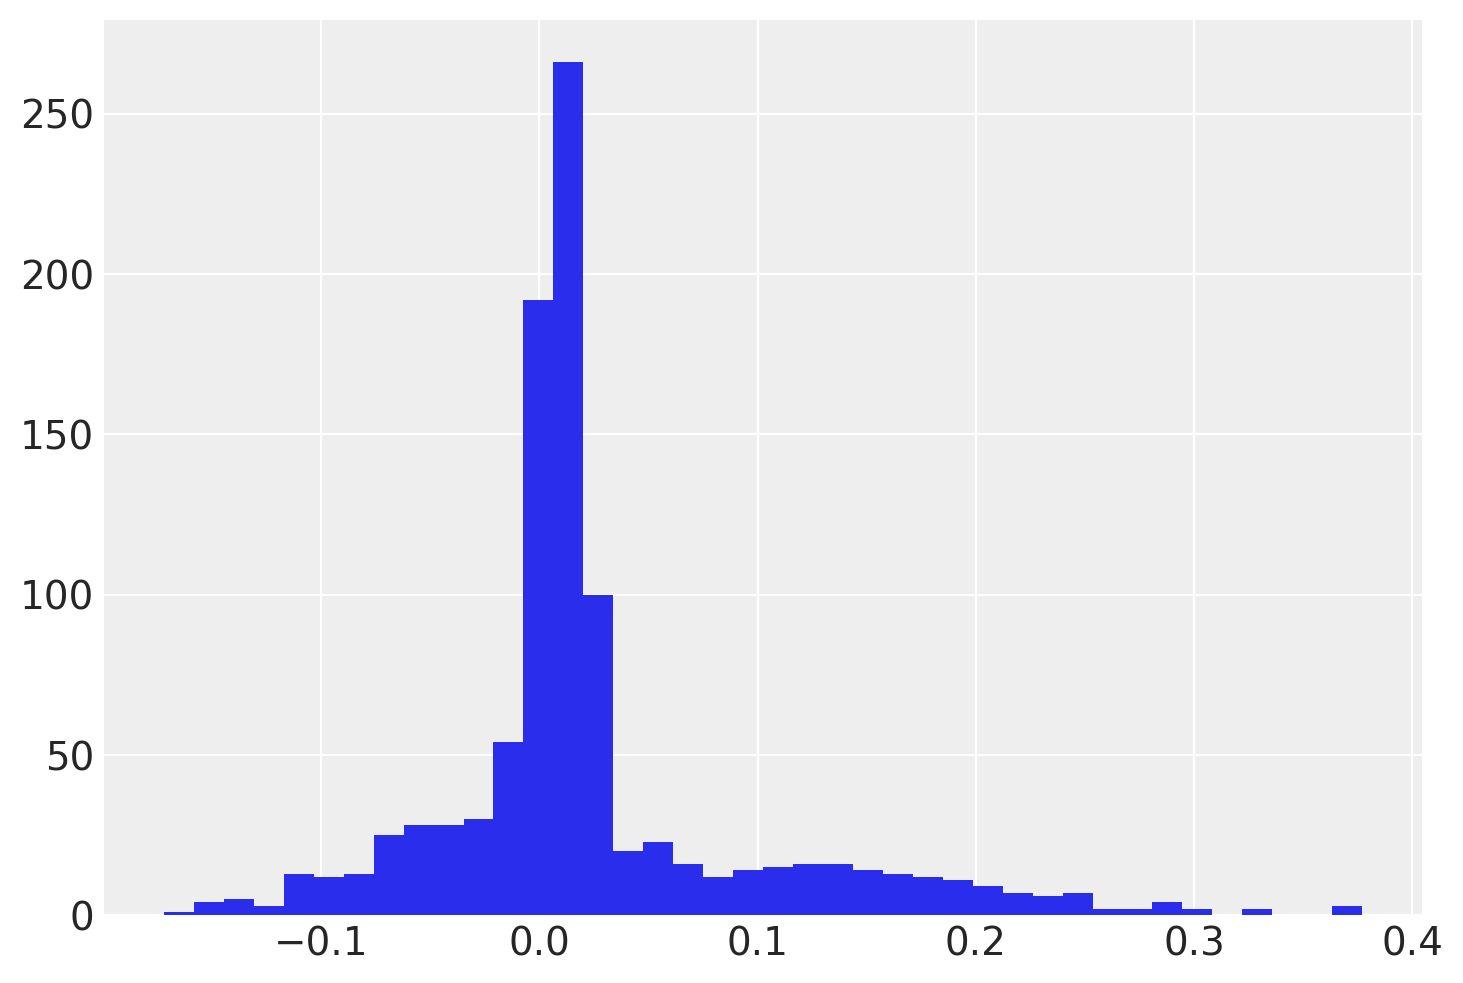

In [ ]:
growth_loc = np.array([0.097, 0.01, -0.048])
growth_scale = np.array([0.1, 0.01, 0.05])

company_type = np.array([company_types.index(val) for val in ds.category.values])

growth_2025 = rng.normal(loc=growth_loc[company_type], scale=growth_scale[company_type])
plt.hist(growth_2025, 40);

In [ ]:
indicator_ps = indicator_likelihoods.T[company_type]
indicators = rng.binomial(n=1, p=indicator_ps).astype(bool)

sns.heatmap(indicators);

NameError: name 'indicator_likelihoods' is not defined

In [ ]:
color_code = -1 * company_type + 1 # 1=hyperscaler, 0=steady-stater, -1=time-bomb
indicators_color_coded = indicators * color_code[:, None]
sns.heatmap(indicators_color_coded, cmap=sns.diverging_palette(20, 145, s=60, as_cmap=True));

In [ ]:
indicators_growth_coded = indicators * growth_2025[:, None]
sns.heatmap(indicators_growth_coded, cmap=sns.diverging_palette(20, 145, s=60, as_cmap=True), center=0)

# Incremental inference with online indicator selection (example for Michael and Felix)

This example focuses on the relationship between indicators and class probabilities/weights instead of the growth forecasts. This is in order to obtain a simple, very fast solution using a Dirichlet conjugate distribution for classes.

The first version below uses expected reduction in entropy as an indicator selection metric.

In [ ]:
# @title
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import digamma, logsumexp

def select_next_indicator(alpha_i, A, candidates):
    """
    Select next indicator using expected reduction in entropy
    """
    K = len(alpha_i)
    max_utility = -float('inf')
    best_j = None

    # Current entropy
    p_k = alpha_i / np.sum(alpha_i)
    current_entropy = -np.sum(p_k * np.log(p_k + 1e-10))

    for j in candidates:
        expected_entropy = 0
        p_xj = np.zeros(2)

        for x_ij in [0, 1]:
            p_xj[x_ij] = np.sum(p_k * (A[j,:]**x_ij * (1-A[j,:])**(1-x_ij)))

            likelihood = A[j,:]**x_ij * (1-A[j,:])**(1-x_ij)
            gamma = p_k * likelihood
            gamma = gamma / np.sum(gamma)

            post_entropy = -np.sum(gamma * np.log(gamma + 1e-10))
            expected_entropy += p_xj[x_ij] * post_entropy

        utility = current_entropy - expected_entropy

        if utility > max_utility:
            max_utility = utility
            best_j = j

    return best_j, max_utility

def plot_active_inference(i, A, true_class=None, n_classes=3):
    """
    Run active inference and plot evolution with confidence intervals
    """
    J = A.shape[0]
    # Class probability estimates
    alpha_i = np.ones(n_classes)
    candidates = list(range(J))

    if true_class is None:
        true_class = np.random.randint(n_classes)
    x_i = np.random.binomial(1, A[:, true_class])

    selected_js = []
    utilities = []
    class_probs = []
    alpha_history = []

    while candidates:
        alpha_history.append(alpha_i.copy())
        p_k = alpha_i / np.sum(alpha_i)
        class_probs.append(p_k)

        j, utility = select_next_indicator(alpha_i, A, candidates)
        utilities.append(utility)
        selected_js.append(j)
        candidates.remove(j)

        x_ij = x_i[j]

        # Direct Bayesian update
        likelihood = A[j,:]**x_ij * (1-A[j,:])**(1-x_ij)
        posterior = p_k * likelihood
        posterior = posterior / np.sum(posterior)
        alpha_i = posterior * np.sum(alpha_i)

    # Create visualization
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

    steps = np.arange(len(utilities))

    # Plot utilities with integer steps
    ax1.plot(steps, utilities, 'b-', label='Expected Reduction in Entropy')
    ax1.set_xlabel('Step')
    ax1.set_ylabel('Expected Utility')
    ax1.legend()
    ax1.grid(True)
    ax1.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

    # Plot class probabilities with confidence intervals
    class_probs = np.array(class_probs)
    alpha_history = np.array(alpha_history)

    for k in range(n_classes):
        color = 'r' if k == true_class else 'gray'
        linestyle = '-' if k == true_class else '--'

        # Mean probability
        ax2.plot(steps, class_probs[:,k], color=color, linestyle=linestyle,
                label=f'Class {k}' + (' (true)' if k == true_class else ''))

        # Confidence intervals from Dirichlet parameters
        var = (alpha_history[:,k] * (np.sum(alpha_history, axis=1) - alpha_history[:,k])) / \
              (np.sum(alpha_history, axis=1)**2 * (np.sum(alpha_history, axis=1) + 1))
        std = np.sqrt(var)

        ax2.fill_between(steps,
                        np.clip(class_probs[:,k] - 2*std, 0, 1),
                        np.clip(class_probs[:,k] + 2*std, 0, 1),
                        color=color, alpha=0.2)

    ax2.set_xlabel('Step')
    ax2.set_ylabel('Class Probability')
    ax2.legend()
    ax2.grid(True)
    ax2.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

    plt.tight_layout()
    return selected_js, utilities, class_probs

# Example usage
np.random.seed(42)
J, K = 20, 5  # 20 indicators, 5 classes
A = np.random.beta(0.5, 0.5, size=(J, K))
selected_js, utilities, class_probs = plot_active_inference(0, A, true_class=2, n_classes=K)

The one above uses the expected log Bayes factor, in a "Bayesian model expansion" fashion, sort of the opposite of [this paper](https://arxiv.org/pdf/1805.07092#page=14.76).

<ipython-input-26-f90b76f2e701>:115: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


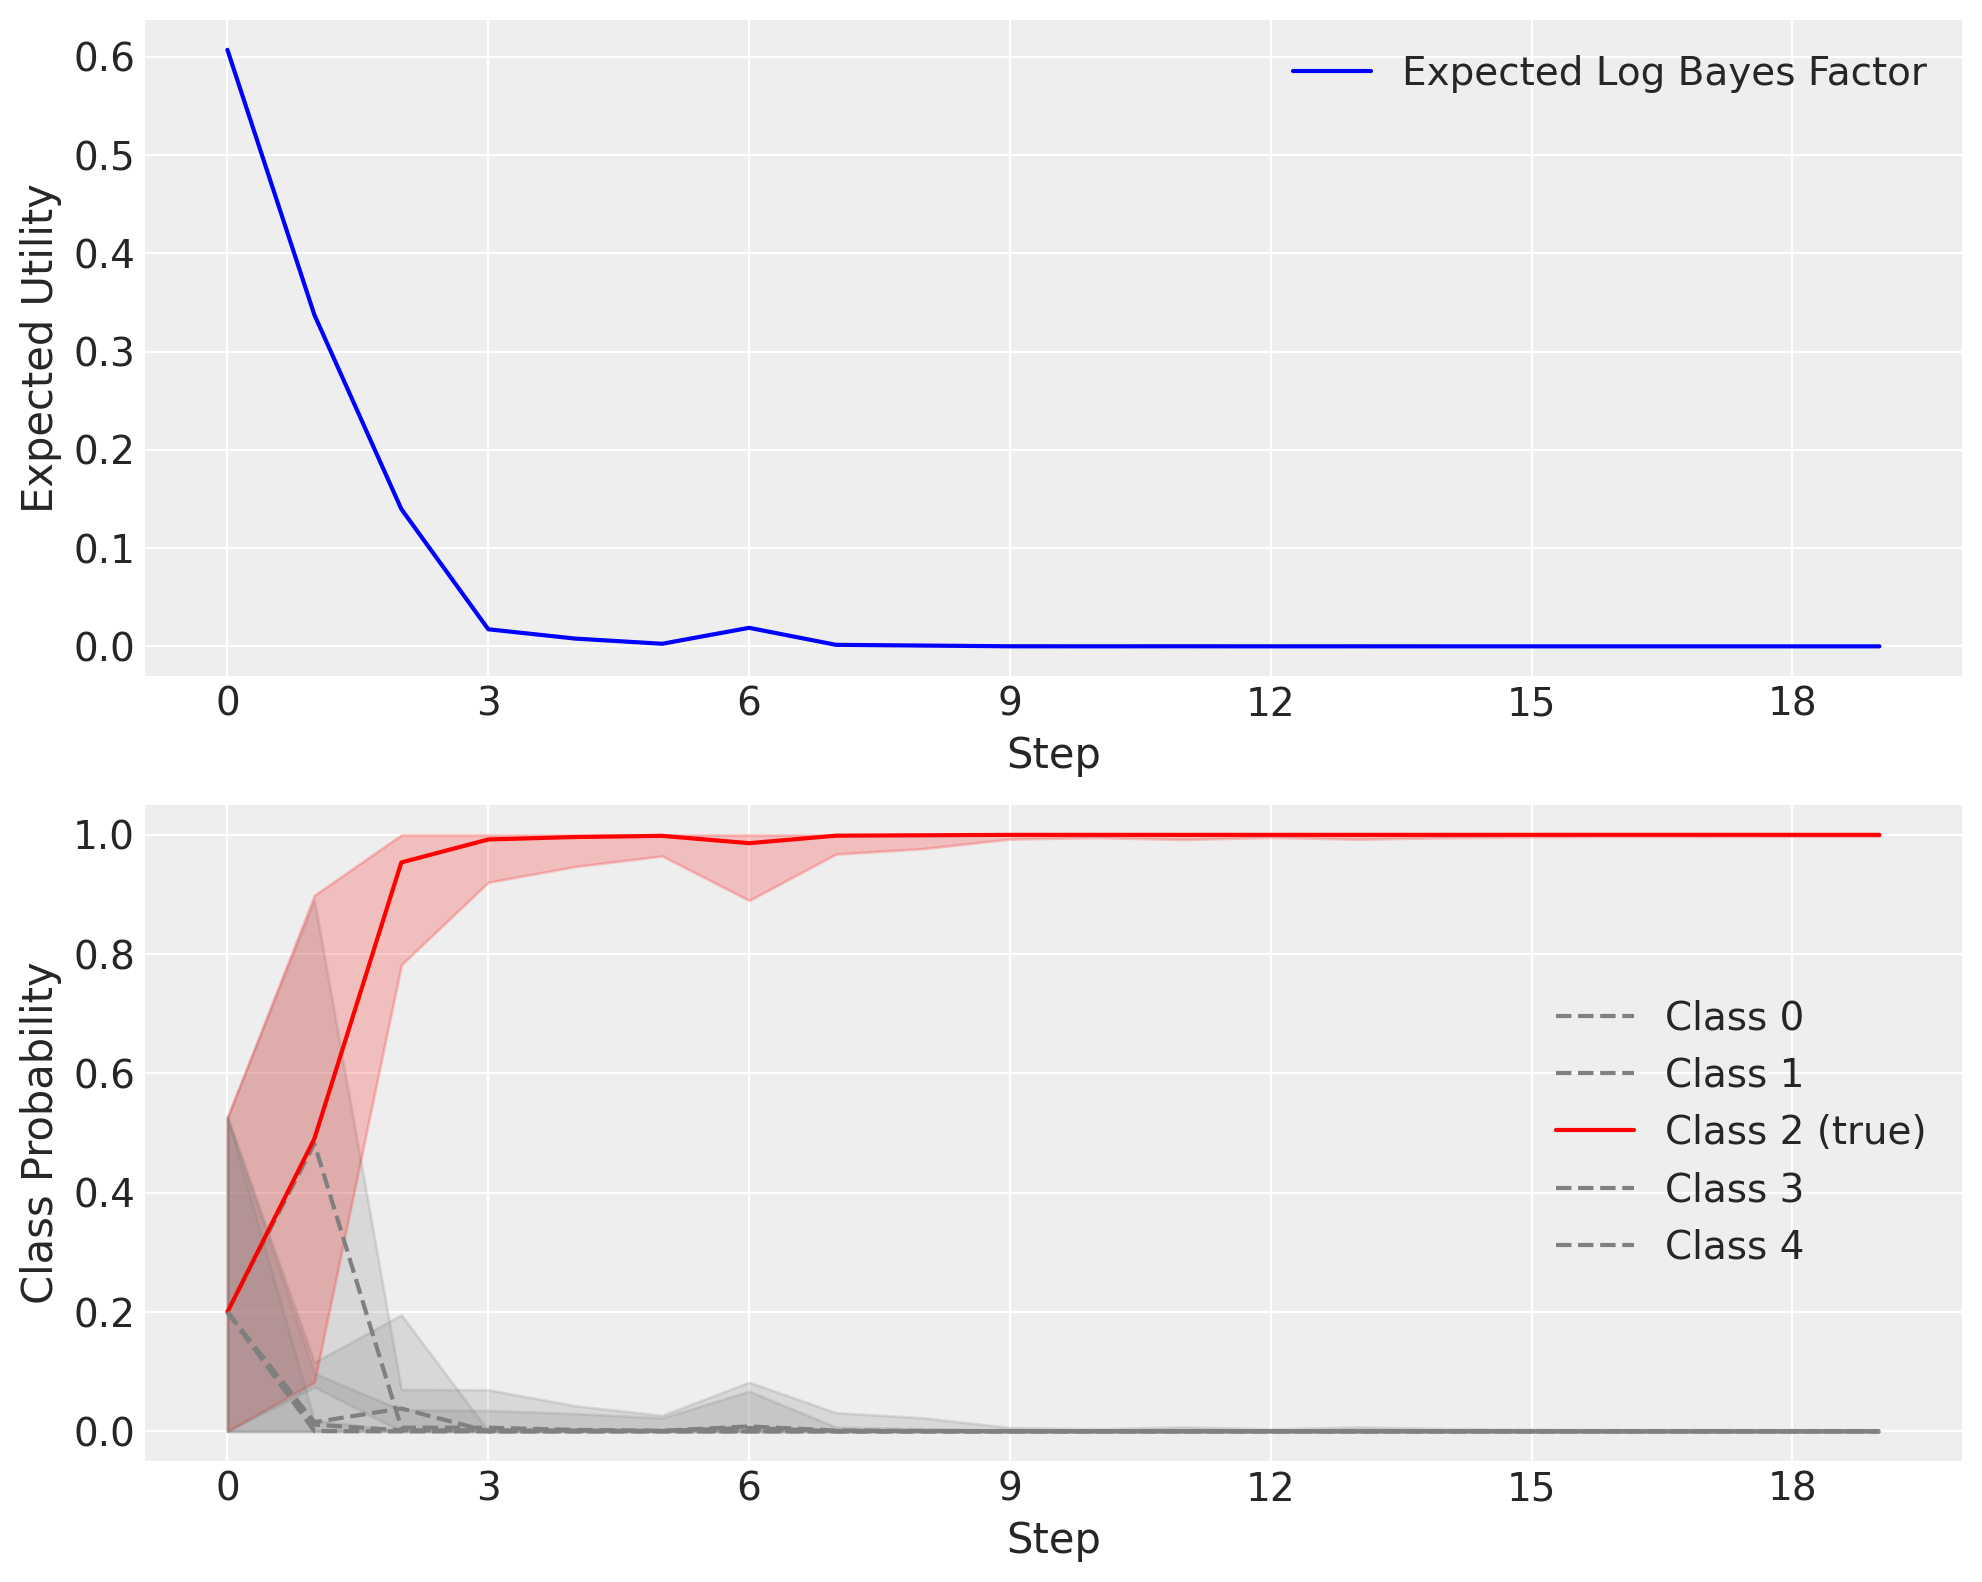

In [ ]:
# @title
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import digamma, logsumexp

def select_next_indicator(alpha_i, A, candidates):
    """
    Select next indicator using expected log Bayes factor
    """
    K = len(alpha_i)
    max_utility = -float('inf')
    best_j = None

    # Current probabilities
    p_k = alpha_i / np.sum(alpha_i)

    for j in candidates:
        utility = 0

        for x_ij in [0, 1]:
            # P(x_ij | current beliefs)
            p_xj = np.sum(p_k * (A[j,:]**x_ij * (1-A[j,:])**(1-x_ij)))

            if p_xj > 0:  # only compute if observation is possible
                # Compute posterior for this potential observation
                likelihood = A[j,:]**x_ij * (1-A[j,:])**(1-x_ij)
                gamma = p_k * likelihood
                gamma = gamma / np.sum(gamma)

                # Expected log Bayes factor
                utility += p_xj * np.sum(gamma * (np.log(likelihood) - np.log(p_xj)))

        if utility > max_utility:
            max_utility = utility
            best_j = j

    return best_j, max_utility

def plot_active_inference(i, A, true_class=None, n_classes=3):
    """
    Run active inference and plot evolution with confidence intervals
    """
    J = A.shape[0]
    alpha_i = np.ones(n_classes)
    candidates = list(range(J))

    if true_class is None:
        true_class = np.random.randint(n_classes)
    x_i = np.random.binomial(1, A[:, true_class])

    selected_js = []
    utilities = []
    class_probs = []
    alpha_history = []

    while candidates:
        alpha_history.append(alpha_i.copy())
        p_k = alpha_i / np.sum(alpha_i)
        class_probs.append(p_k)

        j, utility = select_next_indicator(alpha_i, A, candidates)
        utilities.append(utility)
        selected_js.append(j)
        candidates.remove(j)

        x_ij = x_i[j]

        # Direct Bayesian update
        likelihood = A[j,:]**x_ij * (1-A[j,:])**(1-x_ij)
        posterior = p_k * likelihood
        posterior = posterior / np.sum(posterior)
        alpha_i = posterior * np.sum(alpha_i)

    # Create visualization
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

    steps = np.arange(len(utilities))

    # Plot utilities with integer steps
    ax1.plot(steps, utilities, 'b-', label='Expected Log Bayes Factor')
    ax1.set_xlabel('Step')
    ax1.set_ylabel('Expected Utility')
    ax1.legend()
    ax1.grid(True)
    ax1.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

    # Plot class probabilities with confidence intervals
    class_probs = np.array(class_probs)
    alpha_history = np.array(alpha_history)

    for k in range(n_classes):
        color = 'r' if k == true_class else 'gray'
        linestyle = '-' if k == true_class else '--'

        # Mean probability
        ax2.plot(steps, class_probs[:,k], color=color, linestyle=linestyle,
                label=f'Class {k}' + (' (true)' if k == true_class else ''))

        # Confidence intervals from Dirichlet parameters
        var = (alpha_history[:,k] * (np.sum(alpha_history, axis=1) - alpha_history[:,k])) / \
              (np.sum(alpha_history, axis=1)**2 * (np.sum(alpha_history, axis=1) + 1))
        std = np.sqrt(var)

        ax2.fill_between(steps,
                        np.clip(class_probs[:,k] - 2*std, 0, 1),
                        np.clip(class_probs[:,k] + 2*std, 0, 1),
                        color=color, alpha=0.2)

    ax2.set_xlabel('Step')
    ax2.set_ylabel('Class Probability')
    ax2.legend()
    ax2.grid(True)
    ax2.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

    plt.tight_layout()
    return selected_js, utilities, class_probs

# Example usage
np.random.seed(42)
J, K = 20, 5  # 10 indicators, 5 classes
A = np.random.beta(0.5, 0.5, size=(J, K))
selected_js, utilities, class_probs = plot_active_inference(0, A, true_class=2, n_classes=K)

Now we add back the growth forecast distribution as the main target of our utilities.

<ipython-input-27-6b33d90ec685>:151: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


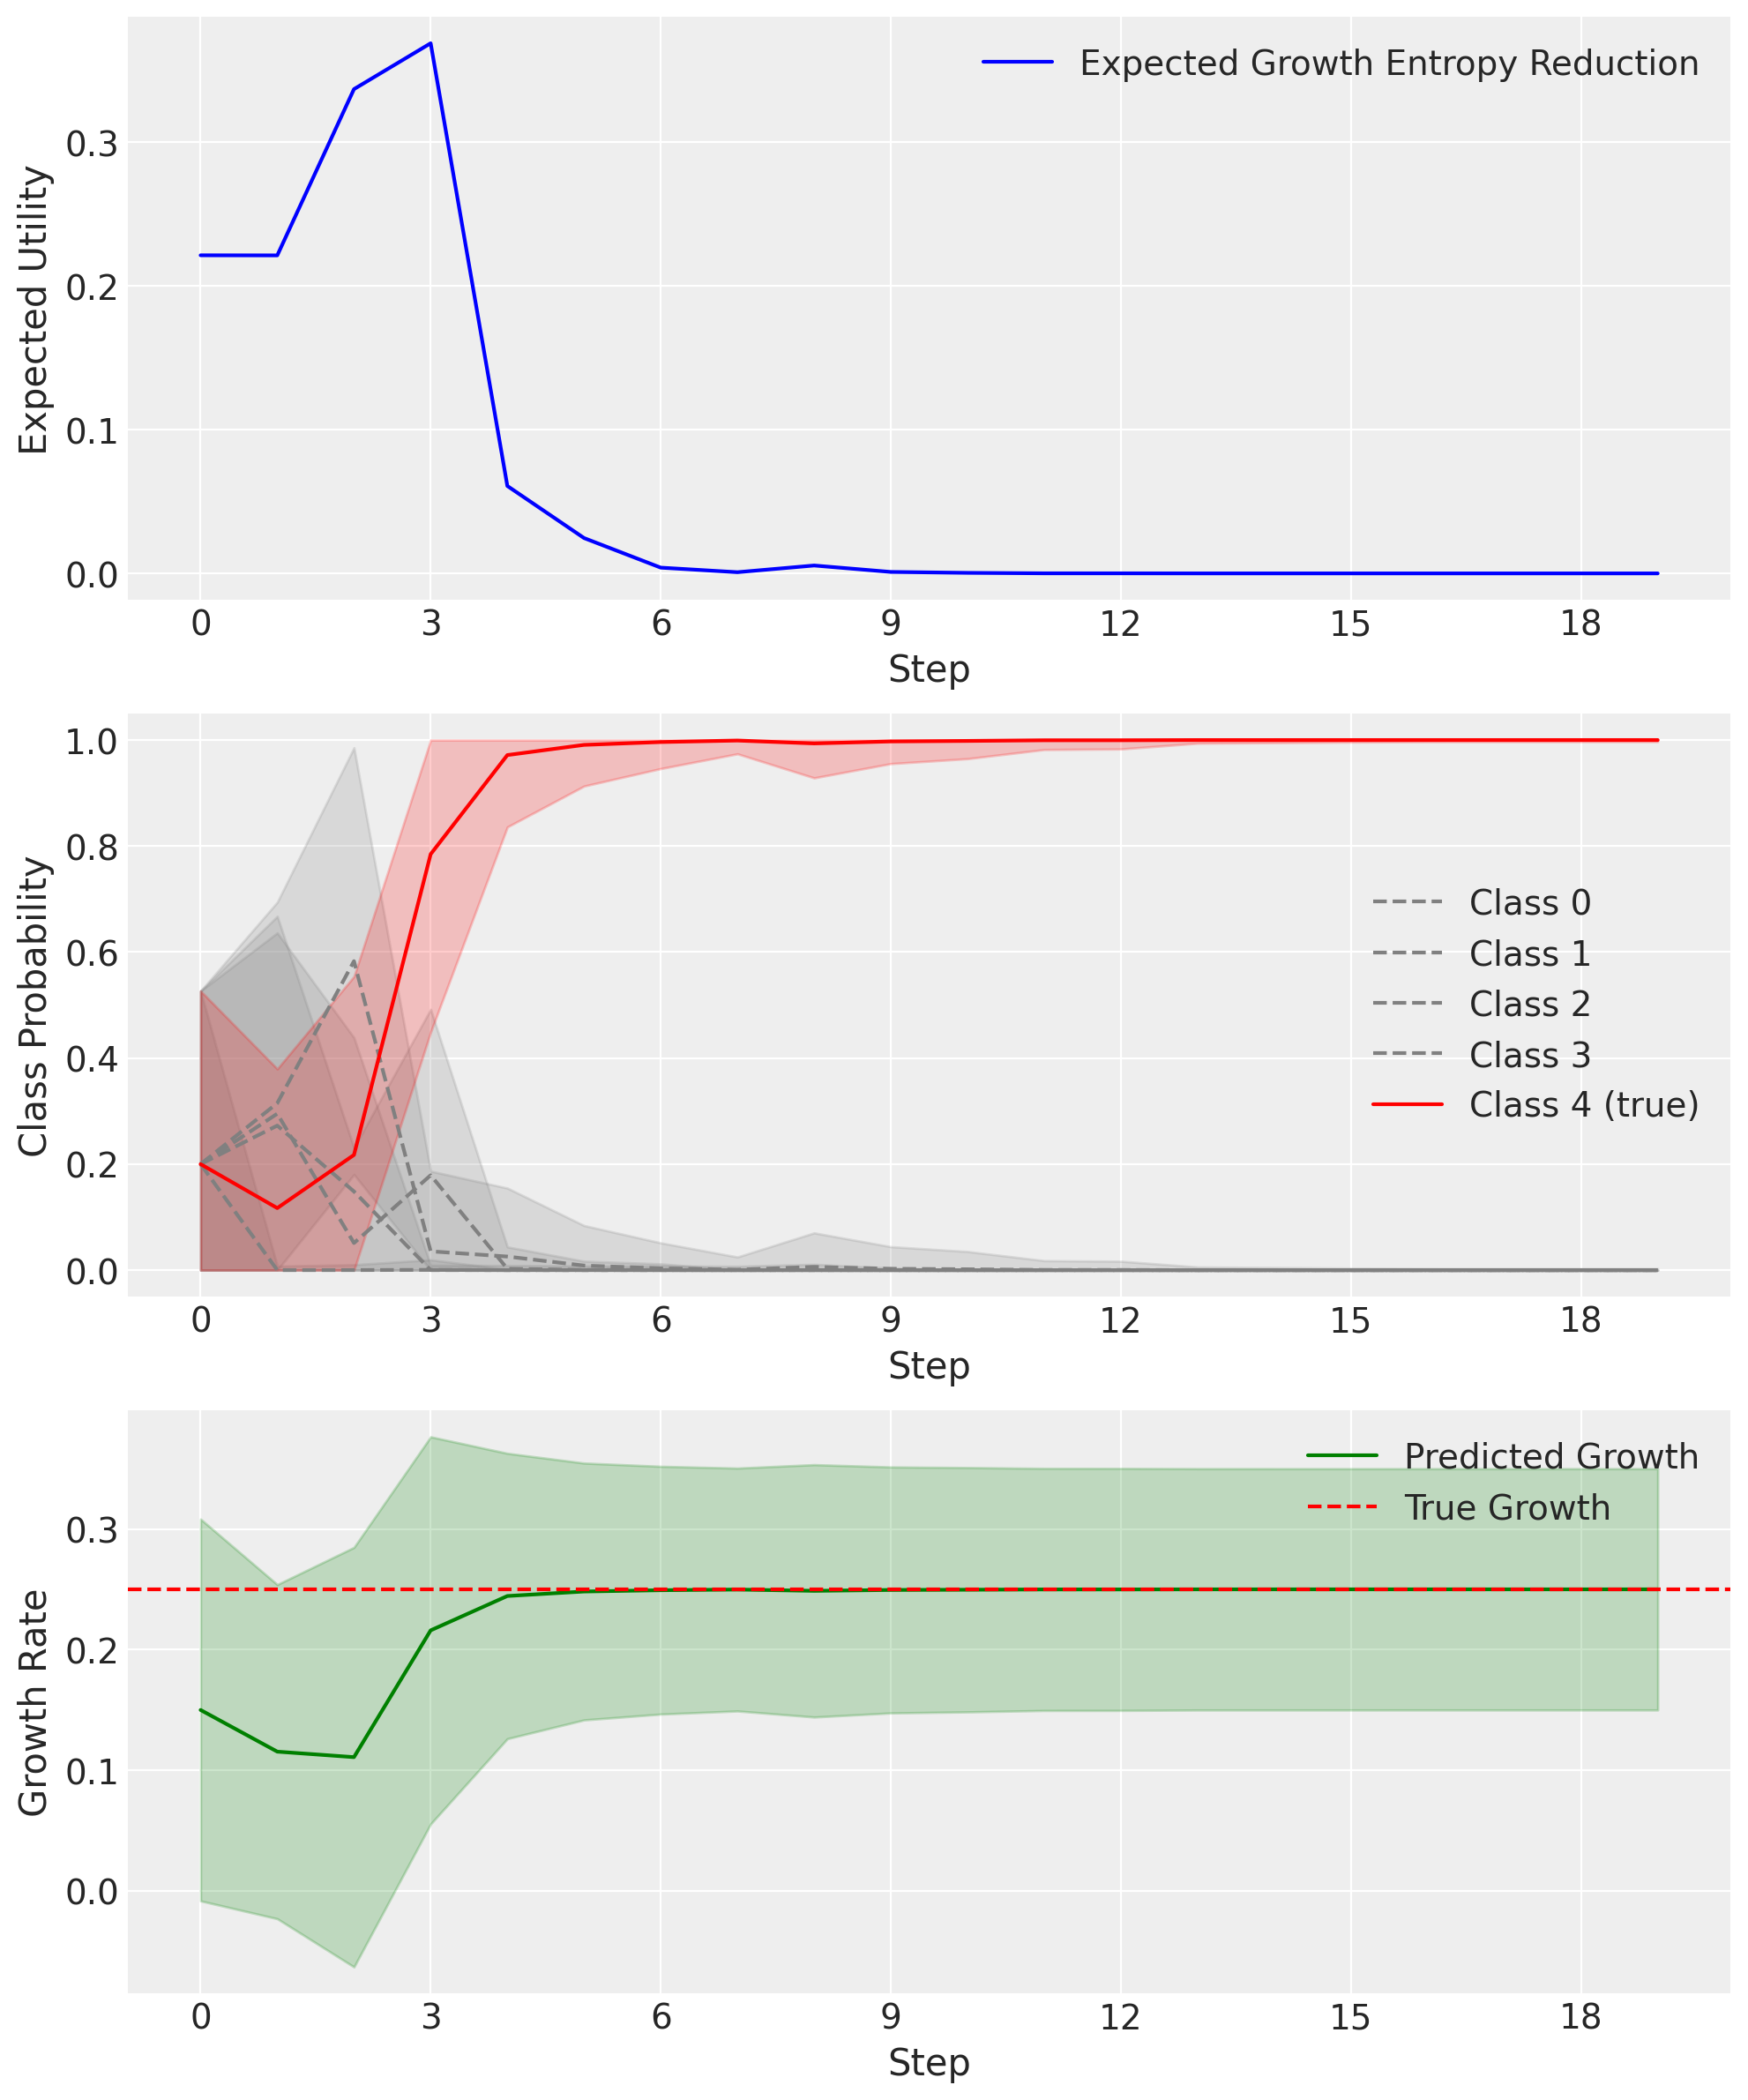

In [ ]:
# @title
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import digamma, logsumexp
from scipy import stats

def mixture_entropy(weights, means, stds):
    """Compute entropy of a Gaussian mixture."""
    x = np.linspace(min(means - 3*max(stds)),
                    max(means + 3*max(stds)),
                    1000)

    pdf = np.zeros_like(x)
    for k in range(len(weights)):
        pdf += weights[k] * stats.norm.pdf(x, means[k], stds[k])

    entropy = -np.sum(pdf[pdf > 0] * np.log(pdf[pdf > 0])) * (x[1] - x[0])
    return entropy

def mixture_stats(weights, means, stds):
    """Compute mean and std of a Gaussian mixture."""
    mean = np.sum(weights * means)
    var = np.sum(weights * (stds**2 + means**2)) - mean**2
    return mean, np.sqrt(var)

def select_next_indicator(alpha_i, A, candidates, mu_g, sigma_g):
    """Select indicator to maximize entropy reduction in growth predictions."""
    K = len(alpha_i)
    max_utility = -float('inf')
    best_j = None

    p_k = alpha_i / np.sum(alpha_i)
    current_entropy = mixture_entropy(p_k, mu_g, sigma_g)

    for j in candidates:
        expected_entropy = 0

        for x_ij in [0, 1]:
            p_xj = np.sum(p_k * (A[j,:]**x_ij * (1-A[j,:])**(1-x_ij)))

            if p_xj > 0:
                likelihood = A[j,:]**x_ij * (1-A[j,:])**(1-x_ij)
                gamma = p_k * likelihood
                gamma = gamma / np.sum(gamma)

                post_entropy = mixture_entropy(gamma, mu_g, sigma_g)
                expected_entropy += p_xj * post_entropy

        utility = current_entropy - expected_entropy

        if utility > max_utility:
            max_utility = utility
            best_j = j

    return best_j, max_utility

def plot_active_inference(i, A, mu_g, sigma_g, true_class=None, n_classes=3):
    """Run active inference and plot evolution including growth forecast."""
    J = A.shape[0]
    alpha_i = np.ones(n_classes)
    candidates = list(range(J))

    if true_class is None:
        true_class = np.random.randint(n_classes)
    x_i = np.random.binomial(1, A[:, true_class])

    selected_js = []
    utilities = []
    class_probs = []
    alpha_history = []
    growth_means = []
    growth_stds = []

    while candidates:
        alpha_history.append(alpha_i.copy())
        p_k = alpha_i / np.sum(alpha_i)
        class_probs.append(p_k)

        # Track growth predictions
        mean_g, std_g = mixture_stats(p_k, mu_g, sigma_g)
        growth_means.append(mean_g)
        growth_stds.append(std_g)

        j, utility = select_next_indicator(alpha_i, A, candidates, mu_g, sigma_g)
        utilities.append(utility)
        selected_js.append(j)
        candidates.remove(j)

        x_ij = x_i[j]

        likelihood = A[j,:]**x_ij * (1-A[j,:])**(1-x_ij)
        posterior = p_k * likelihood
        posterior = posterior / np.sum(posterior)
        alpha_i = posterior * np.sum(alpha_i)

    # Create visualization
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 12))

    steps = np.arange(len(utilities))

    # Plot utilities
    ax1.plot(steps, utilities, 'b-', label='Expected Growth Entropy Reduction')
    ax1.set_xlabel('Step')
    ax1.set_ylabel('Expected Utility')
    ax1.legend()
    ax1.grid(True)
    ax1.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

    # Plot class probabilities
    class_probs = np.array(class_probs)
    alpha_history = np.array(alpha_history)

    for k in range(n_classes):
        color = 'r' if k == true_class else 'gray'
        linestyle = '-' if k == true_class else '--'

        ax2.plot(steps, class_probs[:,k], color=color, linestyle=linestyle,
                label=f'Class {k}' + (' (true)' if k == true_class else ''))

        var = (alpha_history[:,k] * (np.sum(alpha_history, axis=1) - alpha_history[:,k])) / \
              (np.sum(alpha_history, axis=1)**2 * (np.sum(alpha_history, axis=1) + 1))
        std = np.sqrt(var)

        ax2.fill_between(steps,
                        np.clip(class_probs[:,k] - 2*std, 0, 1),
                        np.clip(class_probs[:,k] + 2*std, 0, 1),
                        color=color, alpha=0.2)

    ax2.set_xlabel('Step')
    ax2.set_ylabel('Class Probability')
    ax2.legend()
    ax2.grid(True)
    ax2.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

    # Plot growth forecast
    growth_means = np.array(growth_means)
    growth_stds = np.array(growth_stds)

    ax3.plot(steps, growth_means, 'g-', label='Predicted Growth')
    ax3.fill_between(steps,
                    growth_means - 2*growth_stds,
                    growth_means + 2*growth_stds,
                    color='g', alpha=0.2)
    ax3.axhline(mu_g[true_class], color='r', linestyle='--', label='True Growth')
    ax3.set_xlabel('Step')
    ax3.set_ylabel('Growth Rate')
    ax3.legend()
    ax3.grid(True)
    ax3.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

    plt.tight_layout()
    return selected_js, utilities, class_probs

# Example usage
np.random.seed(42)
J, K = 20, 5  # 10 indicators, 5 classes

# Generate random likelihood matrix
A = np.random.beta(0.5, 0.5, size=(J, K))

# Define growth parameters for each class
mu_g = np.array([0.05, 0.10, 0.15, 0.20, 0.25])  # mean growth rates
sigma_g = np.array([0.02, 0.03, 0.03, 0.04, 0.05])  # standard deviations

# Run and plot
true_class = 4
selected_js, utilities, class_probs = plot_active_inference(0, A, mu_g, sigma_g, true_class=true_class, n_classes=K)

And now with the expected log Bayes factor. Unfortunately this is a lot more expensive, though still not optimized at all!

<ipython-input-28-bad18c44da14>:175: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


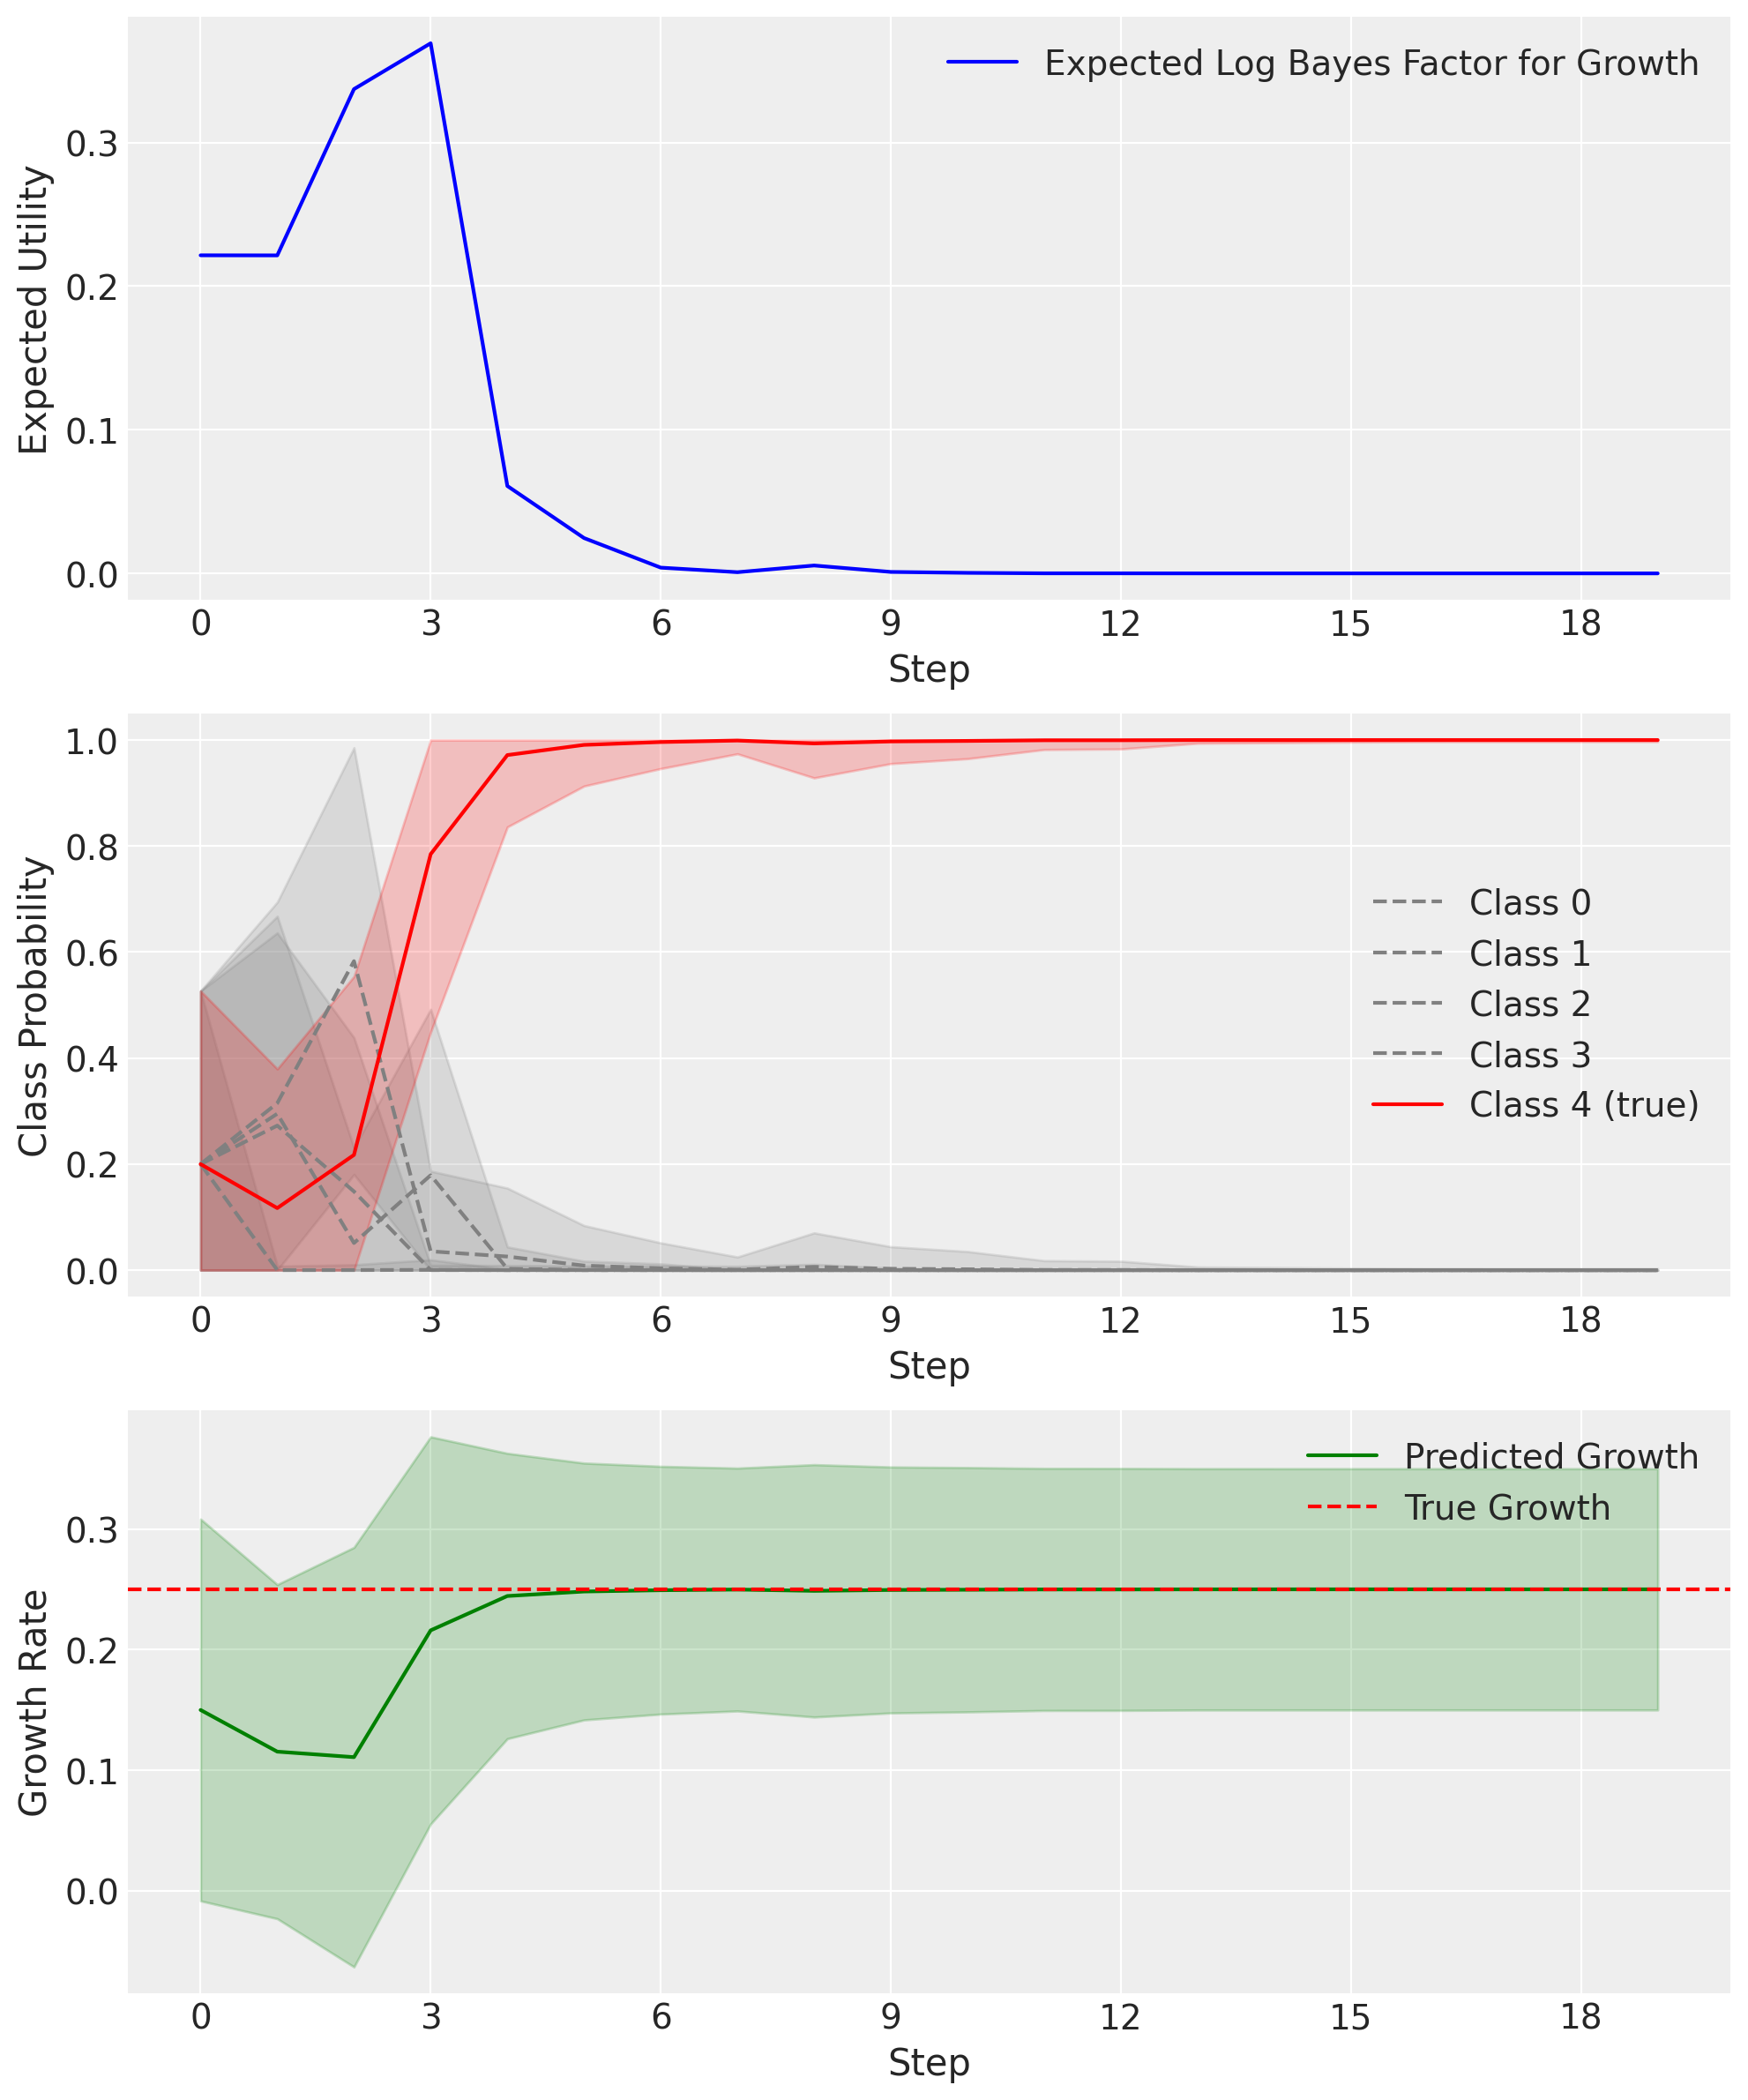

In [ ]:
# @title
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import digamma, logsumexp
from scipy import stats

def mixture_entropy(weights, means, stds):
    """Compute entropy of a Gaussian mixture."""
    x = np.linspace(min(means - 3*max(stds)),
                    max(means + 3*max(stds)),
                    1000)

    pdf = np.zeros_like(x)
    for k in range(len(weights)):
        pdf += weights[k] * stats.norm.pdf(x, means[k], stds[k])

    entropy = -np.sum(pdf[pdf > 0] * np.log(pdf[pdf > 0])) * (x[1] - x[0])
    return entropy

def mixture_stats(weights, means, stds):
    """Compute mean and std of a Gaussian mixture."""
    mean = np.sum(weights * means)
    var = np.sum(weights * (stds**2 + means**2)) - mean**2
    return mean, np.sqrt(var)

def select_next_indicator(alpha_i, A, candidates, mu_g, sigma_g):
    """
    Select next indicator using expected log Bayes factor for growth prediction
    """
    K = len(alpha_i)
    max_utility = -float('inf')
    best_j = None

    # Current probabilities
    p_k = alpha_i / np.sum(alpha_i)

    # Current growth mixture params
    prior_mean, prior_std = mixture_stats(p_k, mu_g, sigma_g)

    for j in candidates:
        utility = 0

        for x_ij in [0, 1]:
            # P(x_ij | current beliefs)
            p_xj = np.sum(p_k * (A[j,:]**x_ij * (1-A[j,:])**(1-x_ij)))

            if p_xj > 0:  # only compute if observation is possible
                # Posterior class probabilities if we observe x_ij
                likelihood = A[j,:]**x_ij * (1-A[j,:])**(1-x_ij)
                gamma = p_k * likelihood
                gamma = gamma / np.sum(gamma)

                # Posterior growth mixture params
                post_mean, post_std = mixture_stats(gamma, mu_g, sigma_g)

                # Expected log Bayes factor is expected log ratio of the densities
                # Note: we need to integrate over possible g values
                g_points = np.linspace(min(mu_g - 3*max(sigma_g)),
                                     max(mu_g + 3*max(sigma_g)),
                                     100)

                for g in g_points:
                    # P(g|posterior)
                    post_prob = sum(gamma[k] * stats.norm.pdf(g, mu_g[k], sigma_g[k])
                                  for k in range(K))
                    # P(g|prior)
                    prior_prob = sum(p_k[k] * stats.norm.pdf(g, mu_g[k], sigma_g[k])
                                   for k in range(K))

                    if post_prob > 0 and prior_prob > 0:
                        # Weight by posterior probability of g
                        utility += p_xj * post_prob * (np.log(post_prob) - np.log(prior_prob)) * \
                                 (g_points[1] - g_points[0])

        if utility > max_utility:
            max_utility = utility
            best_j = j

    return best_j, max_utility

def plot_active_inference(i, A, mu_g, sigma_g, true_class=None, n_classes=3):
    """Run active inference and plot evolution including growth forecast."""
    J = A.shape[0]
    alpha_i = np.ones(n_classes)
    candidates = list(range(J))

    if true_class is None:
        true_class = np.random.randint(n_classes)
    x_i = np.random.binomial(1, A[:, true_class])

    selected_js = []
    utilities = []
    class_probs = []
    alpha_history = []
    growth_means = []
    growth_stds = []

    while candidates:
        alpha_history.append(alpha_i.copy())
        p_k = alpha_i / np.sum(alpha_i)
        class_probs.append(p_k)

        # Track growth predictions
        mean_g, std_g = mixture_stats(p_k, mu_g, sigma_g)
        growth_means.append(mean_g)
        growth_stds.append(std_g)

        j, utility = select_next_indicator(alpha_i, A, candidates, mu_g, sigma_g)
        utilities.append(utility)
        selected_js.append(j)
        candidates.remove(j)

        x_ij = x_i[j]

        likelihood = A[j,:]**x_ij * (1-A[j,:])**(1-x_ij)
        posterior = p_k * likelihood
        posterior = posterior / np.sum(posterior)
        alpha_i = posterior * np.sum(alpha_i)

    # Create visualization
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 12))

    steps = np.arange(len(utilities))

    # Plot utilities
    ax1.plot(steps, utilities, 'b-', label='Expected Log Bayes Factor for Growth')
    ax1.set_xlabel('Step')
    ax1.set_ylabel('Expected Utility')
    ax1.legend()
    ax1.grid(True)
    ax1.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

    # Plot class probabilities
    class_probs = np.array(class_probs)
    alpha_history = np.array(alpha_history)

    for k in range(n_classes):
        color = 'r' if k == true_class else 'gray'
        linestyle = '-' if k == true_class else '--'

        ax2.plot(steps, class_probs[:,k], color=color, linestyle=linestyle,
                label=f'Class {k}' + (' (true)' if k == true_class else ''))

        var = (alpha_history[:,k] * (np.sum(alpha_history, axis=1) - alpha_history[:,k])) / \
              (np.sum(alpha_history, axis=1)**2 * (np.sum(alpha_history, axis=1) + 1))
        std = np.sqrt(var)

        ax2.fill_between(steps,
                        np.clip(class_probs[:,k] - 2*std, 0, 1),
                        np.clip(class_probs[:,k] + 2*std, 0, 1),
                        color=color, alpha=0.2)

    ax2.set_xlabel('Step')
    ax2.set_ylabel('Class Probability')
    ax2.legend()
    ax2.grid(True)
    ax2.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

    # Plot growth forecast
    growth_means = np.array(growth_means)
    growth_stds = np.array(growth_stds)

    ax3.plot(steps, growth_means, 'g-', label='Predicted Growth')
    ax3.fill_between(steps,
                    growth_means - 2*growth_stds,
                    growth_means + 2*growth_stds,
                    color='g', alpha=0.2)
    ax3.axhline(mu_g[true_class], color='r', linestyle='--', label='True Growth')
    ax3.set_xlabel('Step')
    ax3.set_ylabel('Growth Rate')
    ax3.legend()
    ax3.grid(True)
    ax3.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

    plt.tight_layout()
    return selected_js, utilities, class_probs

# Example usage
np.random.seed(42)
J, K = 20, 5  # 10 indicators, 5 classes

# Generate random likelihood matrix
A = np.random.beta(0.5, 0.5, size=(J, K))

# Define growth parameters for each class
mu_g = np.array([0.05, 0.10, 0.15, 0.20, 0.25])  # mean growth rates
sigma_g = np.array([0.02, 0.03, 0.03, 0.04, 0.05])  # standard deviations

# Run and plot
true_class = 4
selected_js, utilities, class_probs = plot_active_inference(0, A, mu_g, sigma_g, true_class=true_class, n_classes=K)

---
